# Neural Association Rule Mining with Human-Readable Explanations
**Data Mining (CSBP320) - Semester Project, Fall 2026** | Dataset: UCI Adult (Census Income)

Team: Mohammed Alali (700044091), Mazin Mohamedahmed (700044312), Ahmed Elmubarak (700041220)

This notebook reproduces the whole project on **Google Colab** (CPU runtime is enough, no GPU needed):

1. a denoising autoencoder (pure NumPy) is trained on one-hot transactions and **proposes association rules** `A => c` from its reconstruction probabilities `P(c | A)`;
2. every proposal is **verified on the data**, so support / confidence / lift are exact;
3. it is compared with **Apriori** and **FP-Growth** (baselines) and an untrained-network ablation, and evaluated for **accuracy, stability, spurious rules and understandability**;
4. plus **explainability** (occlusion, calibration), a **fairness audit** and a **privacy** (Laplace noise) test.

**How to use:** `Runtime -> Run all` (about 6-10 minutes on a Colab CPU). All seeds are fixed (seed 42). Every figure of the report is displayed inline and also saved under `figures/`; the tables are saved under `results/`.

## 0. Install and get the data

In [1]:
!pip -q install "mlxtend>=0.23.4" statsmodels

In [2]:
import os, urllib.request
os.makedirs("data", exist_ok=True); os.makedirs("src", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)

# UCI Adult (Census Income), combined 48,842-row file (no header). Tried in order; the first working source is used.
URLS = [
    "https://raw.githubusercontent.com/mnmalali/Neural-Association-Rule-Mining/main/data/adult-all.csv",
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv",
]
path = "data/adult-all.csv"
ok = False
for u in URLS:
    try:
        urllib.request.urlretrieve(u, path)
        n = sum(1 for _ in open(path))
        if n >= 48000:
            print("downloaded", u, "->", n, "rows"); ok = True; break
    except Exception as e:
        print("could not use", u, "->", type(e).__name__)
if not ok:
    from google.colab import files           # fallback: upload adult-all.csv manually
    up = files.upload(); os.replace(next(iter(up)), path)
print(open(path).readline().strip())

downloaded https://raw.githubusercontent.com/mnmalali/Neural-Association-Rule-Mining/main/data/adult-all.csv -> 48842 rows
39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K


## 1. Source modules
The project's modules are written to `src/` (they are imported by the experiment cells below). `data.py` - preprocessing; `mining.py` - Apriori / FP-Growth baselines and rule statistics; `neural.py` - the autoencoder miner; `explain.py` - plain-English rule explanations; `workflow_fig.py` - Figure 1.

In [3]:
%%writefile src/data.py
"""Data loading and transaction encoding for the UCI Adult (Census Income) dataset."""
import numpy as np
import pandas as pd

COLS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
        "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
        "hours-per-week", "native-country", "income"]

SENSITIVE_ATTRS = ["sex", "race"]          # protected attributes audited in the fairness analysis
TARGET = "income"


def load_raw(path="data/adult-all.csv"):
    df = pd.read_csv(path, header=None, names=COLS, skipinitialspace=True, na_values="?")
    df["income"] = df["income"].str.strip().str.rstrip(".")
    return df


def discretise(df):
    """Turn every column into a categorical attribute (one 'attribute=value' item per cell).
    Missing values simply produce no item (a transaction may have fewer items)."""
    d = pd.DataFrame(index=df.index)
    d["age"] = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120],
                      labels=["<=25", "26-35", "36-45", "46-55", "56-65", ">65"])
    d["workclass"] = df["workclass"].replace({"Self-emp-not-inc": "Self-employed", "Self-emp-inc": "Self-employed",
                                              "Local-gov": "Gov", "State-gov": "Gov", "Federal-gov": "Gov"})
    edu = df["education"].replace({"Preschool": "No-HS", "1st-4th": "No-HS", "5th-6th": "No-HS", "7th-8th": "No-HS",
                                   "9th": "No-HS", "10th": "No-HS", "11th": "No-HS", "12th": "No-HS",
                                   "Assoc-voc": "Associate", "Assoc-acdm": "Associate",
                                   "Prof-school": "Masters+", "Masters": "Masters+", "Doctorate": "Masters+"})
    d["education"] = edu
    d["marital-status"] = df["marital-status"].replace({"Married-civ-spouse": "Married", "Married-AF-spouse": "Married",
                                                        "Married-spouse-absent": "Married-absent",
                                                        "Divorced": "Divorced/Separated", "Separated": "Divorced/Separated"})
    d["occupation"] = df["occupation"]
    d["relationship"] = df["relationship"]
    d["race"] = df["race"].where(df["race"].isin(["White", "Black"]), "Other")
    d["sex"] = df["sex"]
    d["capital-gain"] = pd.cut(df["capital-gain"], [-1, 0, 5000, 1e6], labels=["none", "low", "high"])
    d["capital-loss"] = pd.cut(df["capital-loss"], [-1, 0, 1e6], labels=["none", "some"])
    d["hours-per-week"] = pd.cut(df["hours-per-week"], [-1, 34, 45, 200], labels=["part-time", "full-time", "overtime"])
    d["native-country"] = df["native-country"].map(lambda v: np.nan if pd.isna(v) else ("US" if v == "United-States" else "Non-US"))
    d["income"] = df["income"]
    return d.astype("object")


def to_onehot(cat, min_item_support=0.01):
    """Boolean transaction matrix (rows = people, columns = 'attr=value' items).
    Items rarer than `min_item_support` are dropped (they can never reach the mining threshold)."""
    cols = {}
    for a in cat.columns:
        for v in sorted(cat[a].dropna().unique()):
            cols[f"{a}={v}"] = (cat[a] == v).values
    X = pd.DataFrame(cols, index=cat.index)
    keep = X.columns[X.mean() >= min_item_support]
    return X[keep].astype(bool)


def attr_of(item):
    return item.split("=")[0]


def load_transactions(path="data/adult-all.csv"):
    raw = load_raw(path)
    cat = discretise(raw)
    X = to_onehot(cat)
    return raw, cat, X


Writing src/data.py


In [4]:
%%writefile src/mining.py
"""Classical association-rule mining baselines (Apriori, FP-Growth) and exact rule statistics."""
import time
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

from data import attr_of


def rule_key(ante, cons):
    return " & ".join(sorted(ante)) + " => " + cons


def _rules_from_itemsets(fi, n, min_conf, min_lift):
    if len(fi) == 0:
        return pd.DataFrame(columns=["antecedent", "consequent", "support", "confidence", "lift", "count"])
    r = association_rules(fi, metric="confidence", min_threshold=min_conf, num_itemsets=n)
    r = r[(r["consequents"].map(len) == 1) & (r["lift"] >= min_lift)].copy()
    r["antecedent"] = r["antecedents"].map(lambda s: tuple(sorted(s)))
    r["consequent"] = r["consequents"].map(lambda s: next(iter(s)))
    r["count"] = (r["support"] * n).round().astype(int)
    r = r[["antecedent", "consequent", "support", "confidence", "lift", "count"]].reset_index(drop=True)
    r["key"] = [rule_key(a, c) for a, c in zip(r["antecedent"], r["consequent"])]
    return r


def mine_apriori(X, min_sup=0.05, min_conf=0.8, min_lift=1.2, max_len=4):
    t = time.time()
    fi = apriori(X, min_support=min_sup, use_colnames=True, max_len=max_len)
    r = _rules_from_itemsets(fi, len(X), min_conf, min_lift)
    r.attrs["seconds"] = time.time() - t
    return r


def mine_fpgrowth(X, min_sup=0.05, min_conf=0.8, min_lift=1.2, max_len=4):
    t = time.time()
    fi = fpgrowth(X, min_support=min_sup, use_colnames=True, max_len=max_len)
    r = _rules_from_itemsets(fi, len(X), min_conf, min_lift)
    r.attrs["seconds"] = time.time() - t
    return r


def stats_on(X, rules):
    """Recompute support / confidence / lift of given rules (antecedent tuple, consequent) on dataset X
    (used for held-out evaluation, bootstrap checks etc.)."""
    M = X.values
    col = {c: i for i, c in enumerate(X.columns)}
    n = len(X)
    out = []
    for a, c in zip(rules["antecedent"], rules["consequent"]):
        m = np.ones(n, bool)
        for it in a:
            m &= M[:, col[it]]
        na = m.sum()
        nac = (m & M[:, col[c]]).sum()
        nc = M[:, col[c]].sum()
        conf = nac / na if na else np.nan
        lift = conf / (nc / n) if nc else np.nan
        out.append((nac / n, conf, lift, nac, na))
    return pd.DataFrame(out, columns=["support", "confidence", "lift", "count", "ante_count"], index=rules.index)


def prune_unproductive(rules, X, min_gain=1e-6):
    """Remove rules that are not 'productive' (Webb): a rule A=>c is dropped if some proper subset A' of A
    (non-empty) has confidence(A'=>c) >= confidence(A=>c) - min_gain, i.e. the extra conditions add nothing."""
    if len(rules) == 0:
        return rules
    M = X.values
    col = {c: i for i, c in enumerate(X.columns)}
    n = len(X)
    cache = {}

    def conf(a, c):
        k = (a, c)
        if k not in cache:
            m = np.ones(n, bool)
            for it in a:
                m &= M[:, col[it]]
            cache[k] = (m & M[:, col[c]]).sum() / max(m.sum(), 1)
        return cache[k]

    keep = []
    from itertools import combinations
    for a, c, cf in zip(rules["antecedent"], rules["consequent"], rules["confidence"]):
        ok = True
        for k in range(1, len(a)):
            for sub in combinations(a, k):
                if conf(tuple(sorted(sub)), c) >= cf - min_gain:
                    ok = False
                    break
            if not ok:
                break
        keep.append(ok)
    return rules[np.array(keep)].reset_index(drop=True)


Writing src/mining.py


In [5]:
%%writefile src/neural.py
"""Neural association-rule mining (ARM-AE style) in pure NumPy.

A denoising autoencoder (DAE) is trained on the boolean transaction matrix. Because the input is randomly
masked, the network learns to *complete* partial transactions, i.e. its sigmoid output for item c given an input
that contains only itemset A approximates P(c | A).  Rule candidates A => c are the (A, c) pairs whose
reconstruction probability exceeds a threshold; every candidate is then verified on the data, so all reported
support / confidence / lift values are exact (the network only *proposes*, the data *disposes*)."""
import time
from itertools import combinations
import numpy as np
import pandas as pd

from data import attr_of
from mining import rule_key


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))


class DenoisingAE:
    """D -> h1 -> h2(bottleneck) -> h1 -> D with ReLU hidden layers, sigmoid output, BCE loss, Adam."""

    def __init__(self, d, h1=64, h2=16, seed=0):
        rng = np.random.default_rng(seed)
        self.rng = rng
        sizes = [d, h1, h2, h1, d]
        self.W = [rng.normal(0, np.sqrt(2.0 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(4)]
        self.b = [np.zeros(sizes[i + 1]) for i in range(4)]
        self.m = [np.zeros_like(w) for w in self.W] + [np.zeros_like(b) for b in self.b]
        self.v = [np.zeros_like(w) for w in self.W] + [np.zeros_like(b) for b in self.b]
        self.t = 0
        self.history = []

    def forward(self, x, keep=False):
        acts = [x]
        h = x
        for i in range(4):
            z = h @ self.W[i] + self.b[i]
            h = _sigmoid(z) if i == 3 else np.maximum(z, 0)
            acts.append(h)
        return (h, acts) if keep else h

    def encode(self, x):
        h = x
        for i in range(2):
            h = np.maximum(h @ self.W[i] + self.b[i], 0)
        return h

    def _step(self, x_in, x_tgt, lr, l2):
        out, acts = self.forward(x_in, keep=True)
        n = len(x_in)
        eps = 1e-7
        loss = -np.mean(np.sum(x_tgt * np.log(out + eps) + (1 - x_tgt) * np.log(1 - out + eps), axis=1))
        delta = (out - x_tgt) / n                      # d loss / d z_out for sigmoid + BCE
        gW, gb = [None] * 4, [None] * 4
        for i in range(3, -1, -1):
            gW[i] = acts[i].T @ delta + l2 * self.W[i]
            gb[i] = delta.sum(0)
            if i > 0:
                delta = (delta @ self.W[i].T) * (acts[i] > 0)
        params, grads = self.W + self.b, gW + gb
        self.t += 1
        b1, b2 = 0.9, 0.999
        for k, (p, g) in enumerate(zip(params, grads)):
            self.m[k] = b1 * self.m[k] + (1 - b1) * g
            self.v[k] = b2 * self.v[k] + (1 - b2) * g * g
            mh, vh = self.m[k] / (1 - b1 ** self.t), self.v[k] / (1 - b2 ** self.t)
            p -= lr * mh / (np.sqrt(vh) + 1e-8)
        return loss

    def fit(self, X, epochs=30, batch=256, lr=2e-3, l2=1e-5, mask_range=(0.3, 0.95), val=None):
        """Train as a denoising AE: each row keeps a random fraction (1-mask) of its items (mask ~ U(mask_range))
        so that the network learns P(item | partial transaction); the target is the full transaction."""
        X = X.astype(np.float32)
        n = len(X)
        for ep in range(epochs):
            idx = self.rng.permutation(n)
            tot = 0.0
            for s in range(0, n, batch):
                xb = X[idx[s:s + batch]]
                p = self.rng.uniform(*mask_range, size=(len(xb), 1))
                x_in = xb * (self.rng.random(xb.shape) > p)
                tot += self._step(x_in, xb, lr, l2) * len(xb)
            rec = {"epoch": ep + 1, "train_loss": tot / n}
            if val is not None:
                rec["val_loss"] = self.eval_loss(val, mask_range)
            self.history.append(rec)
        return self

    def eval_loss(self, X, mask_range=(0.3, 0.95)):
        rng = np.random.default_rng(123)
        X = X.astype(np.float32)
        p = rng.uniform(*mask_range, size=(len(X), 1))
        x_in = X * (rng.random(X.shape) > p)
        out = self.forward(x_in)
        eps = 1e-7
        return float(-np.mean(np.sum(X * np.log(out + eps) + (1 - X) * np.log(1 - out + eps), axis=1)))


def frequent_antecedents(X, min_sup=0.05, max_size=3):
    """Cheap level-wise counting of antecedent itemsets (size 1..max_size, all items from distinct attributes).
    Only antecedent *support* is counted here; consequents are chosen by the network."""
    M = X.values
    n, d = M.shape
    items = list(X.columns)
    attr = np.array([attr_of(i) for i in items])
    minc = min_sup * n
    Mf = M.astype(np.float32)
    ante = []
    c1 = M.sum(0)
    L1 = [i for i in range(d) if c1[i] >= minc]
    ante += [(i,) for i in L1]
    if max_size >= 2:
        C = Mf.T @ Mf
        L2 = [(i, j) for i, j in combinations(L1, 2) if attr[i] != attr[j] and C[i, j] >= minc]
        ante += L2
    if max_size >= 3:
        L2s = set(L2)
        for (i, j) in L2:
            m = M[:, i] & M[:, j]
            cnt = m.astype(np.float32) @ Mf
            for k in L1:
                if k > j and attr[k] != attr[i] and attr[k] != attr[j] and cnt[k] >= minc \
                        and (i, k) in L2s and (j, k) in L2s:
                    ante.append((i, j, k))
    return ante


def neural_rules(ae, X, min_sup=0.05, min_conf=0.8, min_lift=1.2, tau=0.75, max_ante=3, ante=None,
                 slack=0.05):
    """Extract rules with a trained autoencoder.
    Returns (verified_rules, candidates) where candidates holds every (A, c) proposed by the network
    together with its predicted probability and (if verify) the exact statistics."""
    t0 = time.time()
    M = X.values
    n, d = M.shape
    items = list(X.columns)
    attr = np.array([attr_of(i) for i in items])
    if ante is None:
        ante = frequent_antecedents(X, min_sup, max_ante)
    V = np.zeros((len(ante), d), np.float32)
    for r, a in enumerate(ante):
        V[r, list(a)] = 1
    P = ae.forward(V)                                    # predicted P(item | antecedent)
    base = M.mean(0)
    asup = np.array([np.logical_and.reduce(M[:, list(a)], axis=1).mean() for a in ante])
    rows = []
    for r, a in enumerate(ante):
        ok = np.ones(d, bool)
        for i in a:
            ok &= attr != attr[i]                        # consequent must come from a different attribute
        # neural proposal: P(c|A) >= tau AND neural estimates of support (supp(A)*P) and lift (P/supp(c)) near their thresholds
        ok &= (P[r] >= tau) & (asup[r] * P[r] >= min_sup * (1 - slack)) & (P[r] / np.maximum(base, 1e-9) >= min_lift * (1 - slack))
        for c in np.where(ok)[0]:
            rows.append((a, c, P[r, c]))
    cand = pd.DataFrame({"a_idx": [x[0] for x in rows], "c_idx": [x[1] for x in rows], "p_nn": [x[2] for x in rows]})
    if len(cand) == 0:
        empty = pd.DataFrame(columns=["antecedent", "consequent", "support", "confidence", "lift", "count", "key", "p_nn"])
        return empty, cand
    # exact verification on the data
    cache = {}
    sup, conf, lift, cnt = [], [], [], []
    for a, c in zip(cand["a_idx"], cand["c_idx"]):
        if a not in cache:
            m = np.ones(n, bool)
            for i in a:
                m &= M[:, i]
            cache[a] = m
        m = cache[a]
        na = m.sum()
        nac = (m & M[:, c]).sum()
        sup.append(nac / n)
        conf.append(nac / na)
        lift.append((nac / na) / base[c])
        cnt.append(nac)
    cand["support"], cand["confidence"], cand["lift"], cand["count"] = sup, conf, lift, cnt
    cand["antecedent"] = [tuple(sorted(items[i] for i in a)) for a in cand["a_idx"]]
    cand["consequent"] = [items[c] for c in cand["c_idx"]]
    cand["key"] = [rule_key(a, c) for a, c in zip(cand["antecedent"], cand["consequent"])]
    ok = (cand["support"] >= min_sup) & (cand["confidence"] >= min_conf) & (cand["lift"] >= min_lift)
    rules = cand[ok].drop(columns=["a_idx", "c_idx"]).reset_index(drop=True)
    cand["verified"] = ok.values
    rules.attrs["seconds"] = time.time() - t0
    return rules, cand


def train_ae(X, seed=0, epochs=30, h1=64, h2=16, val=None):
    ae = DenoisingAE(X.shape[1], h1, h2, seed)
    ae.fit(X.values, epochs=epochs, val=None if val is None else val.values)
    return ae


def occlusion_attribution(ae, X, antecedent, consequent):
    """Explain a rule with the network: how much does the predicted probability of the consequent drop when each
    antecedent item is removed? (leave-one-out occlusion on the reconstruction)."""
    col = {c: i for i, c in enumerate(X.columns)}
    full = np.zeros((1, X.shape[1]), np.float32)
    for it in antecedent:
        full[0, col[it]] = 1
    p_full = float(ae.forward(full)[0, col[consequent]])
    out = {}
    for it in antecedent:
        v = full.copy()
        v[0, col[it]] = 0
        out[it] = p_full - float(ae.forward(v)[0, col[consequent]])
    return p_full, out


Writing src/neural.py


In [6]:
%%writefile src/explain.py
"""Human-readable explanations for rules: natural-language templates + evidence + neural occlusion attribution."""
import numpy as np
from data import attr_of

PHRASE = {
    "age": lambda v: f"are aged {v}" if not v.startswith(("<=", ">")) else (f"are {v[2:]} or younger" if v.startswith("<=") else f"are over {v[1:]}"),
    "workclass": lambda v: f"work in the {v} sector",
    "education": lambda v: f"have {v} level education" if v not in ("HS-grad", "Some-college") else ("finished high school (no college)" if v == "HS-grad" else "attended some college"),
    "marital-status": lambda v: f"are {v.lower()}" if v != "Divorced/Separated" else "are divorced or separated",
    "occupation": lambda v: f"work as {v}",
    "relationship": lambda v: f"have the household role '{v}'",
    "race": lambda v: f"have race recorded as {v}",
    "sex": lambda v: f"are {v.lower()}",
    "capital-gain": lambda v: {"none": "have no capital gains", "low": "have small capital gains (<$5k)", "high": "have large capital gains (>$5k)"}[v],
    "capital-loss": lambda v: {"none": "have no capital losses", "some": "have some capital losses"}[v],
    "hours-per-week": lambda v: {"part-time": "work part-time (<35 h/week)", "full-time": "work full-time (35-45 h/week)", "overtime": "work overtime (>45 h/week)"}[v],
    "native-country": lambda v: "were born in the US" if v == "US" else "were born outside the US",
    "income": lambda v: f"earn {'more than $50K' if v == '>50K' else '$50K or less'} per year",
}
PHRASE_C = {  # consequent phrasing: 'tend to ...'
    "income": lambda v: "earn more than $50K per year" if v == ">50K" else "earn $50K or less per year",
}


def item_text(item):
    a, v = item.split("=", 1)
    return PHRASE[a](v)


def explain_rule(row, base_rate=None, drivers=None, n_total=None):
    ante = list(row["antecedent"])
    cons = row["consequent"]
    cond = ", ".join(item_text(i) for i in ante[:-1]) + (" and " if len(ante) > 1 else "") + item_text(ante[-1])
    conf = row["confidence"]
    n_match = int(round(row["count"] / conf))
    s = (f"People who {cond} {item_text(cons)} in {conf:.0%} of cases "
         f"({int(row['count']):,} of {n_match:,} matching people; {row['lift']:.1f}x the base rate).")
    if drivers and len(ante) > 1:
        top = max(drivers, key=drivers.get)
        s += f" Strongest driver according to the network: '{top}'."
    return s


Writing src/explain.py


In [7]:
%%writefile src/workflow_fig.py
"""Draws the workflow diagram (figures/fig_workflow.png)."""
import matplotlib
import matplotlib.pyplot as plt


def draw(path="figures/fig_workflow.png"):
    fig, ax = plt.subplots(figsize=(10, 4.4)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 44)

    def box(x, y, w, h, t, c="#dbe9f7", fs=10):
        ax.add_patch(plt.Rectangle((x, y), w, h, fc=c, ec="#33506f", lw=1.3, zorder=2))
        ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs, zorder=3)

    def arr(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.5, color="#33506f"), zorder=1)

    box(0.5, 17, 12, 11, "UCI Adult\n48,842 people\n15 attributes")
    box(15, 17, 14, 11, "Pre-processing\nbin numeric cols\none-hot items\n(55 items)")
    box(32, 17, 11, 11, "Split 70/30\nstratified\ntrain / test")
    box(47, 31, 22, 11, "Neural ARM (proposed)\nDenoising autoencoder\n55-64-16-64-55", "#cfe8cf")
    box(47, 16.5, 22, 11, "Rule extraction\nP(c|A) >= tau, estimated\nsupport and lift", "#cfe8cf")
    box(47, 2, 22, 10.5, "Baselines\nApriori, FP-Growth,\nuntrained-AE ablation", "#f7d9d9")
    box(72, 16.5, 11.5, 11, "Exact\nverification\non the data")
    box(86, 26, 13.5, 14, "Evaluation\naccuracy, stability,\nspuriousness,\nunderstandability", "#fff2cc", 9)
    box(86, 5, 13.5, 14, "Explain and audit\nrule cards,\nocclusion drivers,\nfairness, privacy", "#fff2cc", 9)
    arr(12.5, 22.5, 15, 22.5); arr(29, 22.5, 32, 22.5)
    arr(43, 26, 47, 34); arr(43, 20, 47, 8); arr(58, 31, 58, 27.5); arr(69, 22, 72, 22); arr(69, 8, 78, 16.5)
    arr(83.5, 25, 86, 31); arr(83.5, 19, 86, 13)
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show(); plt.close()


if __name__ == "__main__":
    draw()


Writing src/workflow_fig.py


## 2. Experiments

### Setup: imports, helper functions, data loading and train/test split
Imports, the helper functions, the data load and the stratified 70/30 split (seed 42).

In [8]:
from IPython.display import display
import pandas as pd
pd.set_option('display.max_colwidth', 220); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
import json, os, sys, time, warnings
from itertools import combinations
sys.path.insert(0, os.path.abspath("src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score, balanced_accuracy_score
from statsmodels.stats.multitest import multipletests
from mlxtend.frequent_patterns import apriori

import data as D
import mining as MN
import neural as NN
import explain as EX

SEED = 42
MIN_SUP, MIN_CONF, MIN_LIFT = 0.05, 0.80, 1.20     # rule thresholds (all methods)
TAU, SLACK = 0.75, 0.05                             # neural proposal threshold / slack
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
S = {}                                              # summary dictionary written to results/summary.json
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
C_NN, C_AP, C_RND, C_CONS = "#1f77b4", "#d62728", "#7f7f7f", "#2ca02c"


def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", bbox_inches="tight")
    plt.show()
    plt.close()


def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if (a or b) else 1.0


def n_epochs(n):
    batch = 64 if n < 5000 else 256
    return batch, int(np.clip(3000 / np.ceil(n / batch), 40, 300))


def neural_pipeline(Xs, seed, tau=TAU, slack=SLACK, untrained=False, h2=16, min_sup=MIN_SUP, val=None):
    """Train a DAE on Xs and extract rules. Returns (verified rules, all proposals, ae)."""
    batch, ep = n_epochs(len(Xs))
    ae = NN.DenoisingAE(Xs.shape[1], 64, h2, seed)
    if not untrained:
        ae.fit(Xs.values, epochs=ep, batch=batch, val=None if val is None else val.values)
    rules, cand = NN.neural_rules(ae, Xs, min_sup=min_sup, min_conf=MIN_CONF, min_lift=MIN_LIFT, tau=tau, slack=slack)
    return rules, cand, ae


def consensus(rules):
    """Neural-consensus rules: verified by the data AND the network itself is confident (p_nn >= min_conf)."""
    return rules[rules["p_nn"] >= MIN_CONF].reset_index(drop=True) if len(rules) else rules


t_start = time.time()
raw, cat, X = D.load_transactions("data/adult-all.csv")
y = X["income=>50K"].values
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.3, random_state=SEED, stratify=y)
Xtr, Xte = X.iloc[idx_tr].reset_index(drop=True), X.iloc[idx_te].reset_index(drop=True)
cat_tr = cat.iloc[idx_tr].reset_index(drop=True)
S["n_rows"], S["n_items"], S["n_train"], S["n_test"] = len(X), X.shape[1], len(Xtr), len(Xte)
S["avg_items_per_txn"] = float(X.sum(axis=1).mean())
S["pos_rate"] = float(y.mean())
S["missing"] = {k: int(v) for k, v in raw.isna().sum().items() if v > 0}


### dataset description table
**Dataset description** (Table 1 of the report).

In [9]:
desc = []
for a in cat.columns:
    vc = cat[a].value_counts()
    desc.append({"attribute": a, "n_values": len(vc), "values (top 4)": ", ".join(map(str, vc.index[:4])),
                 "missing": int(cat[a].isna().sum()), "sensitive": a in D.SENSITIVE_ATTRS})
pd.DataFrame(desc).to_csv("results/dataset_description.csv", index=False)

display(pd.read_csv('results/dataset_description.csv'))


,attribute,n_values,values (top 4),missing,sensitive
0,age,6,"26-35, 36-45, <=25, 46-55",0,False
1,workclass,5,"Private, Gov, Self-employed, Without-pay",2799,False
2,education,6,"HS-grad, Some-college, Bachelors, No-HS",0,False
3,marital-status,5,"Married, Never-married, Divorced/Separated, Widowed",0,False
4,occupation,14,"Prof-specialty, Craft-repair, Exec-managerial, Adm-clerical",2809,False
5,relationship,6,"Husband, Not-in-family, Own-child, Unmarried",0,False
6,race,3,"White, Black, Other",0,True
7,sex,2,"Male, Female",0,True
8,capital-gain,3,"none, high, low",0,False
9,capital-loss,2,"none, some",0,False


### E1: neural vs classical on the full training set
**E1 - Neural ARM vs Apriori / FP-Growth.** Trains the denoising autoencoder, extracts rules, verifies them on the data and compares with the classical miners and the untrained-network ablation. Shows: training loss, calibration (error analysis), threshold and bottleneck sensitivity.

E1 main comparison


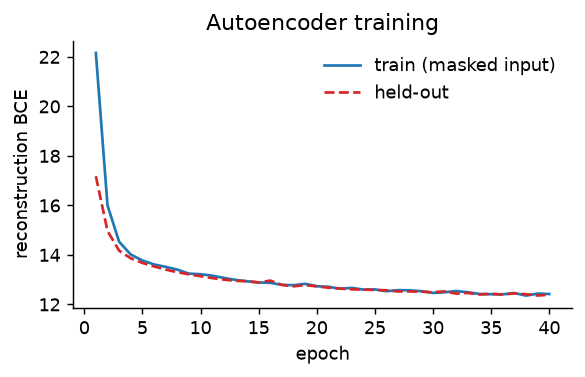

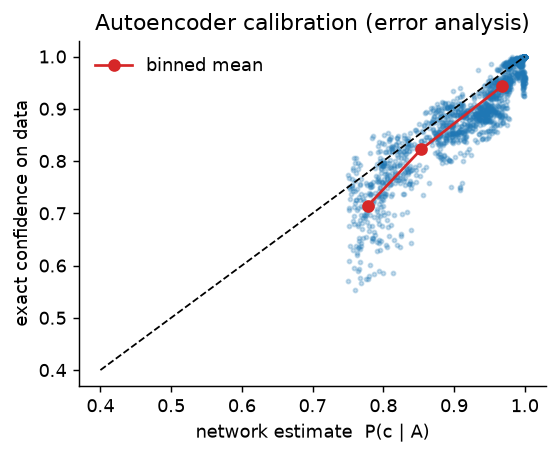

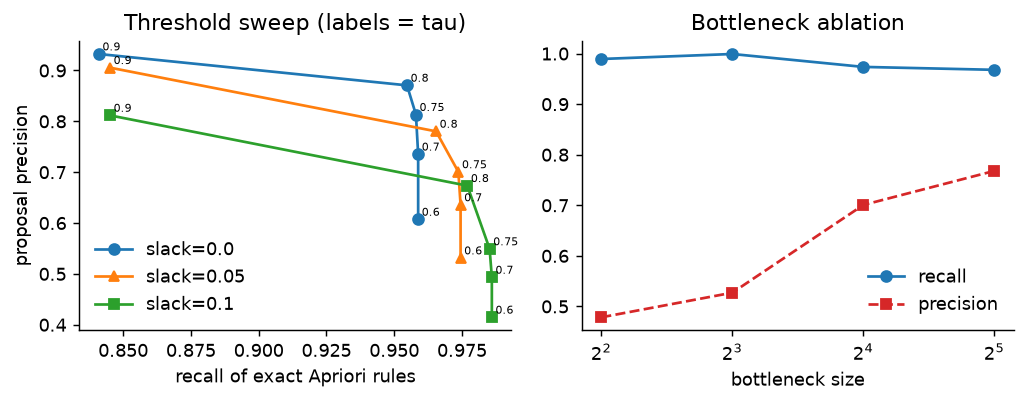

,method,n_rules,recall_vs_apriori,precision_vs_apriori,proposals,proposal_precision,mining_seconds,mean_conf,mean_lift,mean_support
0,Apriori,1214,1.000,1.0,0,NaN,1.328,0.936,1.701,0.115
1,FP-Growth,1214,1.000,1.0,0,NaN,237.300,0.936,1.701,0.115
2,Neural (verified),1182,0.974,1.0,1687,0.701,0.270,0.936,1.711,0.115
3,Neural consensus,1172,0.965,1.0,1687,0.701,0.270,0.937,1.709,0.116
4,Untrained AE (ablation),1,0.001,1.0,144,0.007,0.213,0.837,2.541,0.089


Apriori and FP-Growth return identical rule sets: True


,tau,slack,proposals,precision,recall
0,0.60,0.00,1917,0.607,0.959
1,0.60,0.05,2227,0.531,0.974
2,0.60,0.10,2887,0.415,0.986
3,0.70,0.00,1583,0.735,0.959
4,0.70,0.05,1861,0.636,0.974
5,0.70,0.10,2427,0.493,0.986
6,0.75,0.00,1430,0.813,0.958
7,0.75,0.05,1687,0.701,0.974


,bottleneck,proposals,precision,recall
0,4,2510,0.478,0.989
1,8,2301,0.527,0.999
2,16,1687,0.701,0.974
3,32,1530,0.768,0.968


In [10]:
print("E1 main comparison", flush=True)
ap = MN.mine_apriori(Xtr, MIN_SUP, MIN_CONF, MIN_LIFT)
fp = MN.mine_fpgrowth(Xtr, MIN_SUP, MIN_CONF, MIN_LIFT)
t0 = time.time()
nn_rules, nn_cand, ae = neural_pipeline(Xtr, seed=SEED, val=Xte)
nn_secs = time.time() - t0
rnd_rules, rnd_cand, _ = neural_pipeline(Xtr, seed=SEED, untrained=True)
K_ap = set(ap["key"])
cons_rules = consensus(nn_rules)
rows = []
for name, r, cand in [("Apriori", ap, None), ("FP-Growth", fp, None), ("Neural (verified)", nn_rules, nn_cand),
                      ("Neural consensus", cons_rules, nn_cand), ("Untrained AE (ablation)", rnd_rules, rnd_cand)]:
    k = set(r["key"])
    rows.append({"method": name, "n_rules": len(r), "recall_vs_apriori": len(k & K_ap) / len(K_ap),
                 "precision_vs_apriori": len(k & K_ap) / max(len(k), 1),
                 "proposals": 0 if cand is None else len(cand),
                 "proposal_precision": np.nan if cand is None else float(cand["verified"].mean()),
                 "mining_seconds": r.attrs.get("seconds", np.nan), "mean_conf": r["confidence"].mean(),
                 "mean_lift": r["lift"].mean(), "mean_support": r["support"].mean()})
main = pd.DataFrame(rows)
main.to_csv("results/e1_main_comparison.csv", index=False)
S["e1"] = main.set_index("method").to_dict("index")
S["ae_train_seconds"] = nn_secs
S["ap_fp_identical"] = bool(set(ap["key"]) == set(fp["key"]))
hist = pd.DataFrame(ae.history)
hist.to_csv("results/ae_training_history.csv", index=False)
plt.figure(figsize=(4.6, 3))
plt.plot(hist["epoch"], hist["train_loss"], label="train (masked input)", color=C_NN)
plt.plot(hist["epoch"], hist["val_loss"], label="held-out", color=C_AP, ls="--")
plt.xlabel("epoch"); plt.ylabel("reconstruction BCE"); plt.legend(frameon=False); plt.title("Autoencoder training")
save("fig_training_loss")

# proposal-error analysis: why does the network propose rules that fail verification?
bad = nn_cand[~nn_cand["verified"]]
S["proposal_failures"] = {"fail_support": int((bad["support"] < MIN_SUP).sum()), "fail_confidence": int((bad["confidence"] < MIN_CONF).sum()),
                          "fail_lift": int((bad["lift"] < MIN_LIFT).sum()), "n_bad": int(len(bad))}
# AE calibration: predicted P(c|A) vs exact confidence of the same (A,c)
bins = np.linspace(0.4, 1.0, 7)
cal = nn_cand.copy()
cal["bin"] = pd.cut(cal["p_nn"], bins, include_lowest=True)
calt = cal.groupby("bin", observed=True).agg(pred=("p_nn", "mean"), true=("confidence", "mean"), n=("p_nn", "size")).reset_index()
calt.to_csv("results/ae_calibration.csv", index=False)
S["ae_corr_p_conf"] = float(np.corrcoef(nn_cand["p_nn"], nn_cand["confidence"])[0, 1])
S["ae_mae_p_conf"] = float((nn_cand["p_nn"] - nn_cand["confidence"]).abs().mean())
plt.figure(figsize=(4.4, 3.6))
plt.scatter(nn_cand["p_nn"], nn_cand["confidence"], s=5, alpha=.25, color=C_NN)
plt.plot([.4, 1], [.4, 1], "k--", lw=1)
plt.plot(calt["pred"], calt["true"], "o-", color=C_AP, label="binned mean")
plt.xlabel("network estimate  P(c | A)"); plt.ylabel("exact confidence on data"); plt.legend(frameon=False)
plt.title("Autoencoder calibration (error analysis)")
save("fig_calibration")

# sensitivity: tau / slack grid and bottleneck size (ablations)
ante_tr = NN.frequent_antecedents(Xtr, MIN_SUP, 3)
grid = []
for tau in (0.6, 0.7, 0.75, 0.8, 0.9):
    for sl in (0.0, 0.05, 0.1):
        r, c = NN.neural_rules(ae, Xtr, MIN_SUP, MIN_CONF, MIN_LIFT, tau=tau, slack=sl, ante=ante_tr)
        grid.append({"tau": tau, "slack": sl, "proposals": len(c), "precision": float(c["verified"].mean()) if len(c) else np.nan,
                     "recall": len(set(r["key"]) & K_ap) / len(K_ap)})
pd.DataFrame(grid).to_csv("results/e1_tau_slack_grid.csv", index=False)
bn = []
for h2 in (4, 8, 16, 32):
    r, c, _ = neural_pipeline(Xtr, SEED, h2=h2)
    bn.append({"bottleneck": h2, "proposals": len(c), "precision": float(c["verified"].mean()), "recall": len(set(r["key"]) & K_ap) / len(K_ap)})
pd.DataFrame(bn).to_csv("results/e1_bottleneck.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
g = pd.DataFrame(grid)
for sl, m in zip((0.0, 0.05, 0.1), "o^s"):
    gg = g[g.slack == sl]
    ax[0].plot(gg["recall"], gg["precision"], m + "-", label=f"slack={sl}")
    for _, rr in gg.iterrows():
        ax[0].annotate(f"{rr.tau}", (rr.recall, rr.precision), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax[0].set_xlabel("recall of exact Apriori rules"); ax[0].set_ylabel("proposal precision"); ax[0].legend(frameon=False)
ax[0].set_title("Threshold sweep (labels = tau)")
b = pd.DataFrame(bn)
ax[1].plot(b["bottleneck"], b["recall"], "o-", label="recall", color=C_NN)
ax[1].plot(b["bottleneck"], b["precision"], "s--", label="precision", color=C_AP)
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("bottleneck size"); ax[1].legend(frameon=False); ax[1].set_title("Bottleneck ablation")
save("fig_sensitivity")

display(main.round(3))
print('Apriori and FP-Growth return identical rule sets:', S['ap_fp_identical'])
display(pd.DataFrame(grid).round(3).head(8))
display(pd.DataFrame(bn).round(3))


### E2: held-out accuracy of rules
**E2 - Held-out accuracy.** Support/confidence/lift of the mined rules on the unseen 30% test split; which rules degrade most.

In [11]:
print("E2 held-out accuracy", flush=True)
acc_rows = []
raw_nn = nn_cand.copy()                                   # raw (unverified) network proposals
raw_rnd = rnd_cand.copy()
for name, r in [("Apriori", ap), ("Neural (verified)", nn_rules), ("Neural consensus", cons_rules)]:
    st = MN.stats_on(Xte, r)
    acc_rows.append({"method": name, "n_rules": len(r), "train_conf": r["confidence"].mean(), "test_conf": st["confidence"].mean(),
                     "conf_MAE_train_vs_test": float((st["confidence"] - r["confidence"]).abs().mean()),
                     "test_support_MAE": float((st["support"] - r["support"]).abs().mean()),
                     "replication_rate": float(((st["confidence"] >= MIN_CONF - 0.05) & (st["lift"] >= 1.1)).mean())})
for name, c in [("Neural raw proposals (no verification)", raw_nn), ("Untrained AE raw (ablation)", raw_rnd)]:
    st = MN.stats_on(Xte, c)
    # conf. estimated by the network (p_nn) vs. test confidence
    acc_rows.append({"method": name, "n_rules": len(c), "train_conf": c["p_nn"].mean(), "test_conf": st["confidence"].mean(),
                     "conf_MAE_train_vs_test": float((st["confidence"] - c["p_nn"]).abs().mean()),
                     "test_support_MAE": float((st["support"] - c["support"]).abs().mean()),
                     "replication_rate": float(((st["confidence"] >= MIN_CONF - 0.05) & (st["lift"] >= 1.1) & (st["support"] >= MIN_SUP * 0.8)).mean())})
acc = pd.DataFrame(acc_rows)
acc.to_csv("results/e2_heldout_accuracy.csv", index=False)
S["e2"] = acc.set_index("method").to_dict("index")
# which rules degrade most on test (error analysis)
st_ap = MN.stats_on(Xte, ap)
err = ap.copy()
err["test_conf"], err["test_lift"], err["drop"] = st_ap["confidence"], st_ap["lift"], ap["confidence"] - st_ap["confidence"]
err["ante_len"] = err["antecedent"].map(len)
err["cons_attr"] = err["consequent"].map(D.attr_of)
err.sort_values("drop", ascending=False).head(10)[["key", "confidence", "test_conf", "drop", "count"]].to_csv("results/e2_worst_rules.csv", index=False)
by_len = err.groupby("ante_len").agg(n=("key", "size"), mean_drop=("drop", "mean"), max_drop=("drop", "max")).reset_index()
by_len.to_csv("results/e2_drop_by_antecedent_length.csv", index=False)
by_c = err.groupby("cons_attr").agg(n=("key", "size"), mean_drop=("drop", "mean")).reset_index().sort_values("n", ascending=False)
by_c.to_csv("results/e2_drop_by_consequent_attribute.csv", index=False)
S["e2_drop_by_len"] = by_len.set_index("ante_len").to_dict("index")

display(acc.round(3))
display(by_len.round(3))


E2 held-out accuracy


,method,n_rules,train_conf,test_conf,conf_MAE_train_vs_test,test_support_MAE,replication_rate
0,Apriori,1214,0.936,0.937,0.005,0.002,1.000
1,Neural (verified),1182,0.936,0.937,0.005,0.002,1.000
2,Neural consensus,1172,0.937,0.938,0.005,0.002,1.000
3,Neural raw proposals (no verification),1687,0.922,0.893,0.035,0.002,0.898
4,Untrained AE raw (ablation),144,0.778,0.131,0.647,0.001,0.007


,ante_len,n,mean_drop,max_drop
0,1,19,-0.000,0.013
1,2,240,-0.001,0.022
2,3,955,-0.001,0.027


### E3: sample-size sweep (spurious rules at small n)
**E3 - Sample-size sweep.** Rules mined, held-out replication rate and confidence error as the training set shrinks (5 random subsets per size). Takes about 1-2 minutes.

E3 sample-size sweep


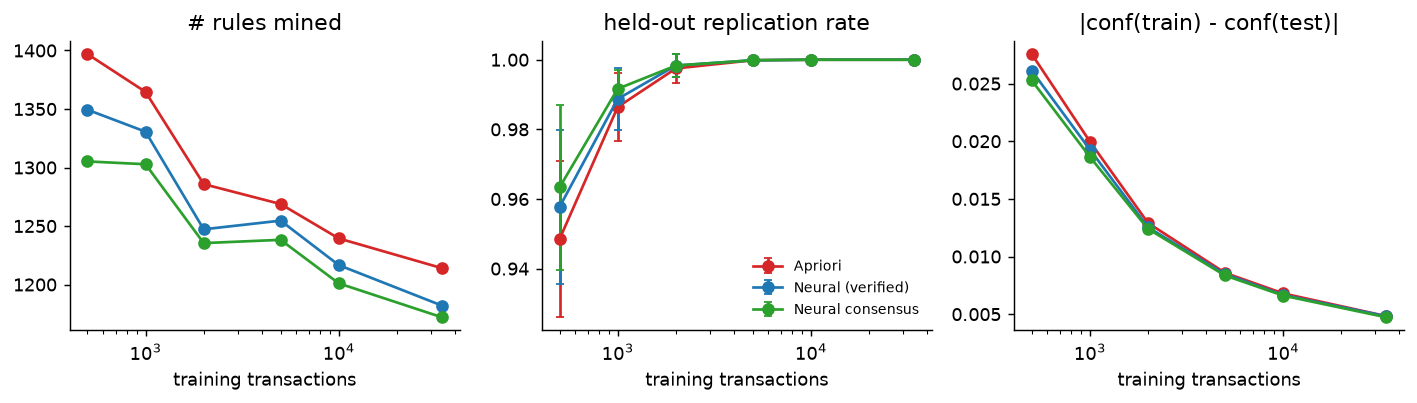

,method,n,n_rules,replication,repl_sd,conf_err
0,Apriori,500,1397.0,0.948,0.022,0.028
1,Apriori,1000,1364.6,0.986,0.010,0.020
2,Apriori,2000,1285.8,0.997,0.004,0.013
3,Apriori,5000,1268.8,1.000,0.000,0.009
4,Apriori,10000,1239.4,1.000,0.000,0.007
5,Apriori,34189,1214.0,1.000,NaN,0.005
6,Neural (verified),500,1349.4,0.958,0.022,0.026
7,Neural (verified),1000,1330.6,0.989,0.009,0.019
8,Neural (verified),2000,1247.2,0.998,0.003,0.013
9,Neural (verified),5000,1254.6,1.000,0.000,0.008


In [12]:
print("E3 sample-size sweep", flush=True)
sweep = []
for n in (500, 1000, 2000, 5000, 10000, len(Xtr)):
    for rep in range(5 if n < len(Xtr) else 1):
        rs = np.random.default_rng(SEED + rep)
        sub = Xtr.iloc[rs.choice(len(Xtr), n, replace=False)].reset_index(drop=True) if n < len(Xtr) else Xtr
        a = MN.mine_apriori(sub, MIN_SUP, MIN_CONF, MIN_LIFT)
        r, c, _ = neural_pipeline(sub, SEED + rep)
        cr = consensus(r)
        for name, rr in [("Apriori", a), ("Neural (verified)", r), ("Neural consensus", cr)]:
            if len(rr) == 0:
                sweep.append({"n": n, "rep": rep, "method": name, "n_rules": 0, "replication": np.nan, "conf_err": np.nan})
                continue
            st = MN.stats_on(Xte, rr)
            sweep.append({"n": n, "rep": rep, "method": name, "n_rules": len(rr),
                          "replication": float(((st["confidence"] >= MIN_CONF - 0.05) & (st["lift"] >= 1.1)).mean()),
                          "conf_err": float((st["confidence"] - rr["confidence"]).abs().mean())})
sw = pd.DataFrame(sweep)
sw.to_csv("results/e3_sample_size_sweep.csv", index=False)
swm = sw.groupby(["method", "n"]).agg(n_rules=("n_rules", "mean"), replication=("replication", "mean"), repl_sd=("replication", "std"),
                                      conf_err=("conf_err", "mean")).reset_index()
swm.to_csv("results/e3_sample_size_summary.csv", index=False)
S["e3"] = {m: g.set_index("n")[["n_rules", "replication", "conf_err"]].to_dict("index") for m, g in swm.groupby("method")}
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for m, col in [("Apriori", C_AP), ("Neural (verified)", C_NN), ("Neural consensus", C_CONS)]:
    g = swm[swm.method == m]
    ax[0].plot(g["n"], g["n_rules"], "o-", color=col, label=m)
    ax[1].errorbar(g["n"], g["replication"], yerr=g["repl_sd"].fillna(0), fmt="o-", color=col, label=m, capsize=2)
    ax[2].plot(g["n"], g["conf_err"], "o-", color=col, label=m)
for a_, t in zip(ax, ["# rules mined", "held-out replication rate", "|conf(train) - conf(test)|"]):
    a_.set_xscale("log"); a_.set_xlabel("training transactions"); a_.set_title(t)
ax[1].legend(frameon=False, fontsize=8)
save("fig_sample_size")

display(swm.round(3))


### E4: stability
**E4 - Stability.** Bootstrap resamples (new network seed each time) at the full training size and at n = 2,000; pairwise Jaccard of the rule sets; seed-only runs. Takes about 2 minutes.

E4 stability


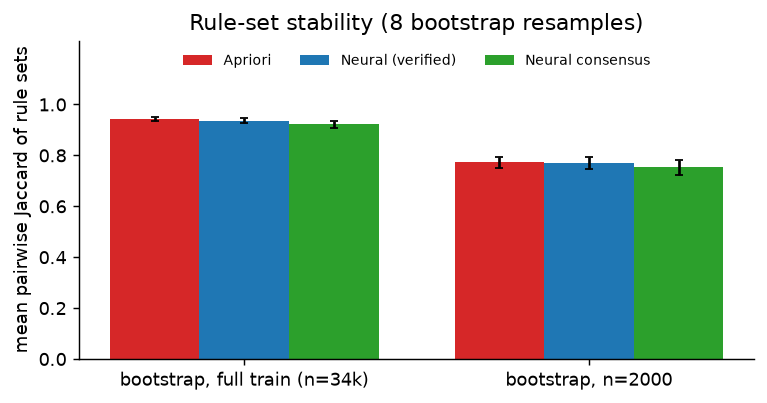

,setting,method,mean_jaccard,sd_jaccard,mean_n_rules,share_rules_in_90pct_runs
0,full train,Apriori,0.943,0.008,1213.500,0.866
1,full train,Neural (verified),0.937,0.011,1203.000,0.846
2,full train,Neural consensus,0.921,0.015,1188.125,0.800
3,n=2000,Apriori,0.773,0.023,1244.000,0.523
4,n=2000,Neural (verified),0.769,0.023,1220.000,0.506
5,n=2000,Neural consensus,0.754,0.029,1199.250,0.477
6,"full train, seeds only",Neural (verified),0.984,0.008,1202.800,NaN


In [13]:
print("E4 stability", flush=True)
stab_rows, retention = [], {}
B = 8
for label, n in [("full train", len(Xtr)), ("n=2000", 2000)]:
    sets = {"Apriori": [], "Neural (verified)": [], "Neural consensus": []}
    lifts = {"Apriori": [], "Neural (verified)": []}
    for b in range(B):
        rs = np.random.default_rng(1000 + b)
        sub = Xtr.iloc[rs.choice(len(Xtr), n, replace=True)].reset_index(drop=True)   # bootstrap resample
        a = MN.mine_apriori(sub, MIN_SUP, MIN_CONF, MIN_LIFT)
        r, c, _ = neural_pipeline(sub, 2000 + b)                                       # different seed too
        sets["Apriori"].append(a); sets["Neural (verified)"].append(r); sets["Neural consensus"].append(consensus(r))
    for m, lst in sets.items():
        js = [jaccard(x["key"], y_["key"]) for x, y_ in combinations(lst, 2)]
        stab_rows.append({"setting": label, "method": m, "mean_jaccard": float(np.mean(js)), "sd_jaccard": float(np.std(js)),
                          "mean_n_rules": float(np.mean([len(x) for x in lst]))})
        cnt = pd.Series([k for x in lst for k in x["key"]]).value_counts() / B
        retention[(label, m)] = float((cnt >= 0.9).sum() / max(len(cnt), 1))      # share of ever-seen rules found in >=90% of runs
        stab_rows[-1]["share_rules_in_90pct_runs"] = retention[(label, m)]
# seed-only stability of the network (same data, different initialisation)
seed_sets = [neural_pipeline(Xtr, 3000 + s)[0] for s in range(5)]
sj = [jaccard(x["key"], y_["key"]) for x, y_ in combinations(seed_sets, 2)]
stab_rows.append({"setting": "full train, seeds only", "method": "Neural (verified)", "mean_jaccard": float(np.mean(sj)), "sd_jaccard": float(np.std(sj)),
                  "mean_n_rules": float(np.mean([len(x) for x in seed_sets])), "share_rules_in_90pct_runs": np.nan})
stab = pd.DataFrame(stab_rows)
stab.to_csv("results/e4_stability.csv", index=False)
S["e4"] = stab.to_dict("records")
fig, ax = plt.subplots(figsize=(6, 3.2))
w = .26
labs = ["full train", "n=2000"]
for i, (m, col) in enumerate([("Apriori", C_AP), ("Neural (verified)", C_NN), ("Neural consensus", C_CONS)]):
    v = [stab[(stab.setting == l) & (stab.method == m)]["mean_jaccard"].iloc[0] for l in labs]
    s_ = [stab[(stab.setting == l) & (stab.method == m)]["sd_jaccard"].iloc[0] for l in labs]
    ax.bar(np.arange(2) + (i - 1) * w, v, w, yerr=s_, color=col, label=m, capsize=2)
ax.set_xticks(range(2)); ax.set_xticklabels(["bootstrap, full train (n=34k)", "bootstrap, n=2000"])
ax.set_ylabel("mean pairwise Jaccard of rule sets"); ax.set_ylim(0, 1.25); ax.set_yticks([0, .2, .4, .6, .8, 1.0]); ax.legend(frameon=False, fontsize=8, loc="upper center", ncol=3)
ax.set_title("Rule-set stability (8 bootstrap resamples)")
save("fig_stability")

display(stab.round(3))


### E5: spurious rules (permutation null + FDR + productivity)
**E5 - Spurious rules.** Permutation null (every dependency destroyed, so every rule found is false), Fisher exact test with BH-FDR, and the productivity (redundancy) test.

In [14]:
print("E5 spurious rules", flush=True)
null_rows = []
for n in (1000, 5000):
    for rep in range(5):
        rs = np.random.default_rng(SEED + 77 + rep)
        sub_cat = cat_tr.iloc[rs.choice(len(cat_tr), n, replace=False)].reset_index(drop=True)
        perm = sub_cat.apply(lambda col: col.sample(frac=1, random_state=int(rs.integers(1e9))).values)   # destroy ALL dependencies
        Xp = D.to_onehot(perm, 0.01)
        a = MN.mine_apriori(Xp, MIN_SUP, MIN_CONF, MIN_LIFT)
        r, c, _ = neural_pipeline(Xp, SEED + rep)
        null_rows.append({"n": n, "rep": rep, "Apriori": len(a), "Neural (verified)": len(r), "Neural consensus": len(consensus(r))})
nul = pd.DataFrame(null_rows)
nul.to_csv("results/e5_permutation_null.csv", index=False)
S["e5_null"] = nul.groupby("n")[["Apriori", "Neural (verified)", "Neural consensus"]].mean().to_dict("index")


def fisher_fdr(r, Xs, alpha=0.05):
    st = MN.stats_on(Xs, r)
    n = len(Xs)
    nc = np.array([Xs[c].sum() for c in r["consequent"]])
    p = []
    for nac, na, ncc in zip(st["count"], st["ante_count"], nc):
        p.append(fisher_exact([[nac, na - nac], [ncc - nac, n - na - ncc + nac]], alternative="greater")[1])
    q = multipletests(p, method="fdr_bh")[1]
    return float((q < alpha).mean())


fdr_rows = []
rs = np.random.default_rng(SEED)
sub = Xtr.iloc[rs.choice(len(Xtr), 1000, replace=False)].reset_index(drop=True)
a1 = MN.mine_apriori(sub, MIN_SUP, MIN_CONF, MIN_LIFT)
r1, _, _ = neural_pipeline(sub, SEED)
for name, rr in [("Apriori", a1), ("Neural (verified)", r1), ("Neural consensus", consensus(r1))]:
    pr = MN.prune_unproductive(rr, sub)
    fdr_rows.append({"method": name, "n_rules": len(rr), "share_significant_BH_q05": fisher_fdr(rr, sub) if len(rr) else np.nan,
                     "share_productive": len(pr) / max(len(rr), 1)})
for name, rr in [("Apriori", ap), ("Neural (verified)", nn_rules), ("Neural consensus", cons_rules)]:
    pr = MN.prune_unproductive(rr, Xtr)
    fdr_rows.append({"method": name + " [full train]", "n_rules": len(rr), "share_significant_BH_q05": fisher_fdr(rr, Xtr),
                     "share_productive": len(pr) / len(rr)})
pd.DataFrame(fdr_rows).to_csv("results/e5_fdr_productivity.csv", index=False)
S["e5_fdr"] = fdr_rows

display(nul)
display(pd.DataFrame(fdr_rows).round(3))


E5 spurious rules


,n,rep,Apriori,Neural (verified),Neural consensus
0,1000,0,5,1,0
1,1000,1,0,0,0
2,1000,2,14,14,14
3,1000,3,7,5,5
4,1000,4,0,0,0
5,5000,0,0,0,0
6,5000,1,0,0,0
7,5000,2,0,0,0
8,5000,3,0,0,0
9,5000,4,0,0,0


,method,n_rules,share_significant_BH_q05,share_productive
0,Apriori,1429,1.0,0.275
1,Neural (verified),1410,1.0,0.272
2,Neural consensus,1377,1.0,0.270
3,Apriori [full train],1214,1.0,0.419
4,Neural (verified) [full train],1182,1.0,0.409
5,Neural consensus [full train],1172,1.0,0.409


### E6: understandability + explanations
**E6 - Understandability and explanations.** Redundancy pruning, rule-length statistics, natural-language rule cards, and the occlusion explanation figure.

In [15]:
print("E6 understandability", flush=True)
pruned = MN.prune_unproductive(cons_rules, Xtr)
und = []
for name, r in [("Apriori (raw)", ap), ("Neural consensus (raw)", cons_rules), ("Neural consensus + productivity pruning", pruned)]:
    L = r["antecedent"].map(len)
    und.append({"rule set": name, "n_rules": len(r), "mean_conditions": L.mean(), "share_<=2_conditions": float((L <= 2).mean()),
                "distinct_attributes_in_consequents": r["consequent"].map(D.attr_of).nunique()})
pd.DataFrame(und).to_csv("results/e6_understandability.csv", index=False)
S["e6"] = und
# rule cards (natural-language explanations with neural occlusion drivers)
top = pruned[pruned["consequent"].isin(["income=>50K", "income=<=50K"])].sort_values("lift", ascending=False)
# class rules for the high-income class come from the lower-support CAR mining of E7 -> computed below, so cards are built after E7
top = pd.concat([top[top.consequent == "income=<=50K"].head(2),
                 pruned[~pruned["consequent"].str.startswith("income")].sort_values("lift", ascending=False).head(3)])
cards = []
for _, r in top.iterrows():
    p_full, drv = NN.occlusion_attribution(ae, Xtr, r["antecedent"], r["consequent"])
    cards.append({"rule": r["key"], "support": r["support"], "confidence": r["confidence"], "lift": r["lift"], "count": int(r["count"]),
                  "network_P": p_full, "drivers": json.dumps({k: round(v, 3) for k, v in drv.items()}),
                  "explanation": EX.explain_rule(r, drivers=drv)})
cards = pd.DataFrame(cards)
cards.to_csv("results/e6_rule_cards.csv", index=False)
L = {n: r["antecedent"].map(len).value_counts().sort_index() for n, r in [("Apriori", ap), ("Neural consensus", cons_rules), ("Neural cons. + pruning", pruned)]}
pd.DataFrame(L).fillna(0).astype(int).to_csv("results/e6_rule_length_distribution.csv")

display(pd.DataFrame(und).round(3))
display(cards[['rule', 'confidence', 'lift', 'explanation']])


E6 understandability


,rule set,n_rules,mean_conditions,share_<=2_conditions,distinct_attributes_in_consequents
0,Apriori (raw),1214,2.771,0.213,6
1,Neural consensus (raw),1172,2.769,0.215,6
2,Neural consensus + productivity pruning,479,2.637,0.324,6


,rule,confidence,lift,explanation
0,capital-gain=none & hours-per-week=part-time & relationship=Own-child => income=<=50K,0.998541,1.312639,"People who have no capital gains, work part-time (<35 h/week) and have the household role 'Own-child' earn $50K or less per year in 100% of cases (2,053 of 2,056 matching people; 1.3x the base rate). Strongest driver..."
1,hours-per-week=part-time & marital-status=Never-married & relationship=Own-child => income=<=50K,0.998016,1.311949,"People who work part-time (<35 h/week), are never-married and have the household role 'Own-child' earn $50K or less per year in 100% of cases (2,012 of 2,016 matching people; 1.3x the base rate). Strongest driver acc..."
2,hours-per-week=part-time & marital-status=Never-married & relationship=Own-child => age=<=25,0.920139,4.689718,"People who work part-time (<35 h/week), are never-married and have the household role 'Own-child' are 25 or younger in 92% of cases (1,855 of 2,016 matching people; 4.7x the base rate). Strongest driver according to ..."
3,hours-per-week=part-time & native-country=US & relationship=Own-child => age=<=25,0.895133,4.562269,"People who work part-time (<35 h/week), were born in the US and have the household role 'Own-child' are 25 or younger in 90% of cases (1,784 of 1,993 matching people; 4.6x the base rate). Strongest driver according t..."
4,capital-gain=none & hours-per-week=part-time & relationship=Own-child => age=<=25,0.893969,4.556336,"People who have no capital gains, work part-time (<35 h/week) and have the household role 'Own-child' are 25 or younger in 89% of cases (1,838 of 2,056 matching people; 4.6x the base rate). Strongest driver according..."


### E7: downstream class-association-rule classifier + fairness
**E7 - Downstream use, fairness audit.** Class-association-rule classifier vs decision tree, group-fairness metrics with and without sex/race, sensitive-rule audit and proxy rules.

E7 downstream + fairness


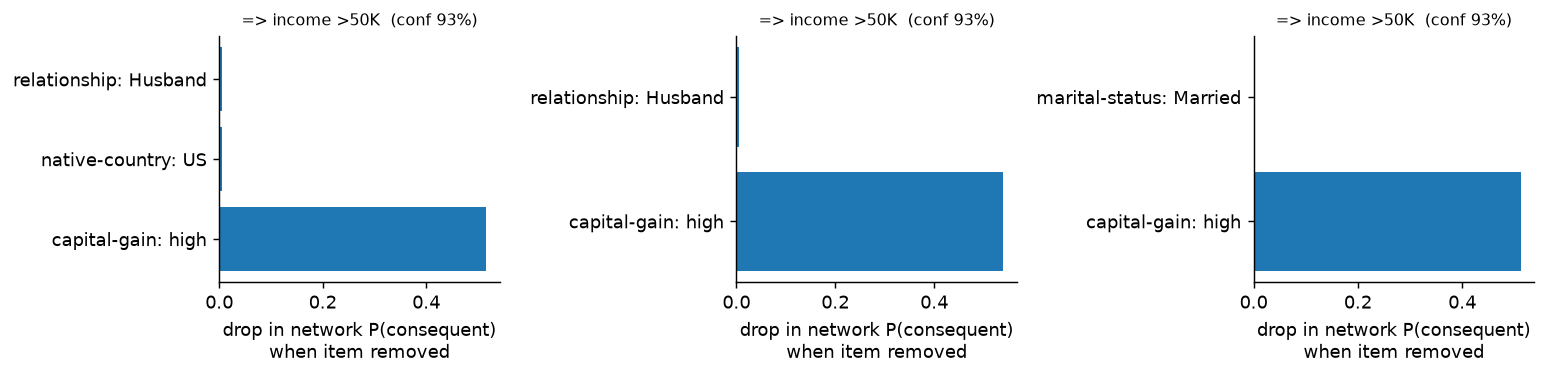

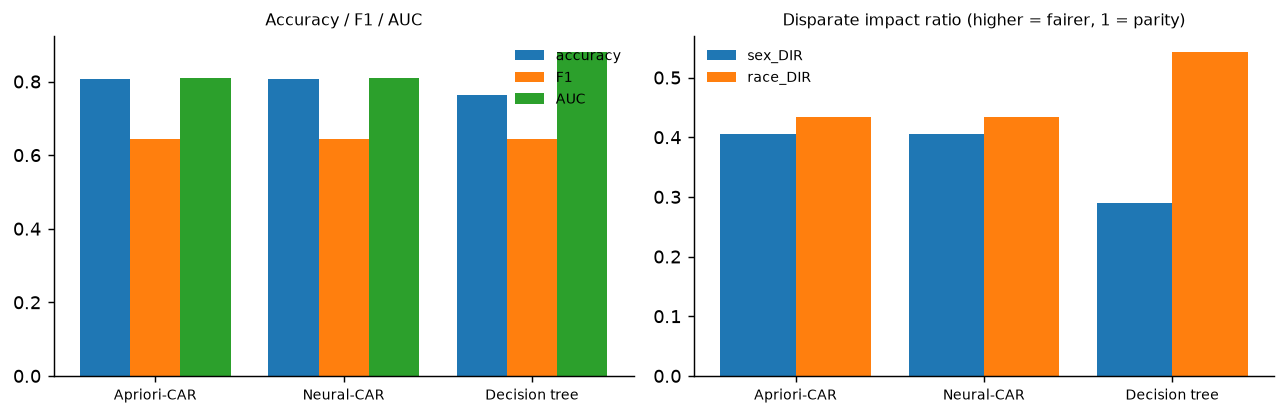

,variant,model,n_rules,accuracy,balanced_acc,precision,recall,F1,AUC,seconds,sex_DPD,sex_DIR,sex_EOD,race_DPD,race_DIR,race_EOD
0,with sex/race,Apriori-CAR,139.0,0.806,0.780,0.575,0.729,0.643,0.810,3.681,0.225,0.406,0.082,0.183,0.434,0.171
1,with sex/race,Neural-CAR,109.0,0.806,0.780,0.575,0.729,0.643,0.810,6.619,0.225,0.406,0.082,0.183,0.434,0.171
2,with sex/race,Decision tree (depth 5),NaN,0.764,0.806,0.504,0.885,0.642,0.879,NaN,0.392,0.290,0.180,0.202,0.542,0.041
3,with sex/race,Majority class,0.0,0.761,0.500,0.000,0.000,0.000,0.500,0.000,0.000,NaN,0.000,0.000,NaN,0.000
4,without sex/race,Apriori-CAR,91.0,0.813,0.782,0.589,0.723,0.649,0.810,1.787,0.211,0.422,0.075,0.174,0.441,0.156
5,without sex/race,Neural-CAR,66.0,0.820,0.775,0.609,0.690,0.647,0.799,6.317,0.196,0.419,0.095,0.157,0.455,0.122
6,without sex/race,Decision tree (depth 5),NaN,0.764,0.806,0.504,0.885,0.642,0.879,NaN,0.392,0.290,0.180,0.202,0.542,0.041
7,without sex/race,Majority class,0.0,0.761,0.500,0.000,0.000,0.000,0.500,0.000,0.000,NaN,0.000,0.000,NaN,0.000


,key,support,confidence,lift
1148,hours-per-week=part-time & race=White & relationship=Own-child => income=<=50K,0.054,0.997,1.310
494,age=<=25 & hours-per-week=part-time & race=White => income=<=50K,0.066,0.996,1.309
479,age=<=25 & race=White & relationship=Own-child => income=<=50K,0.093,0.995,1.308
453,age=<=25 & marital-status=Never-married & sex=Female => income=<=50K,0.076,0.995,1.308
480,age=<=25 & relationship=Own-child & sex=Male => income=<=50K,0.059,0.994,1.306
1040,hours-per-week=part-time & marital-status=Never-married & race=White => income=<=50K,0.076,0.994,1.306
448,age=<=25 & marital-status=Never-married & race=White => income=<=50K,0.143,0.992,1.305
1150,capital-gain=none & relationship=Own-child & sex=Female => income=<=50K,0.065,0.992,1.305


,key,confidence,lift
1084,occupation=Exec-managerial & race=White & relationship=Husband => sex=Male,1.0,1.492
1085,capital-gain=none & occupation=Exec-managerial & relationship=Husband => sex=Male,1.0,1.492
1086,capital-loss=none & occupation=Exec-managerial & relationship=Husband => sex=Male,1.0,1.492
1087,native-country=US & occupation=Exec-managerial & relationship=Husband => sex=Male,1.0,1.492
1096,occupation=Prof-specialty & race=White & relationship=Husband => sex=Male,1.0,1.492


Share of rules mentioning sex/race: 0.574


In [16]:
print("E7 downstream + fairness", flush=True)
TARGET = "income=>50K"
CAR_SUP, CAR_CONF, CAR_LIFT = 0.02, 0.60, 1.5


def car_apriori(Xs, drop_cols=()):
    """Class association rules (consequent = income>50K) from classical Apriori itemsets."""
    Z = Xs.drop(columns=list(drop_cols))
    fi = apriori(Z, min_support=CAR_SUP, use_colnames=True, max_len=4)
    sup = {frozenset(s): v for s, v in zip(fi["itemsets"], fi["support"])}
    base = Z[TARGET].mean()
    out = []
    for s, v in sup.items():
        if TARGET in s and len(s) > 1:
            a = s - {TARGET}
            conf = v / sup[a]
            if conf >= CAR_CONF and conf / base >= CAR_LIFT:
                out.append((tuple(sorted(a)), TARGET, v, conf, conf / base))
    return pd.DataFrame(out, columns=["antecedent", "consequent", "support", "confidence", "lift"])


def car_neural(Xs, drop_cols=()):
    Z = Xs.drop(columns=list(drop_cols))
    ae_ = NN.DenoisingAE(Z.shape[1], 64, 16, SEED)
    ae_.fit(Z.values, epochs=40)
    ante = NN.frequent_antecedents(Z, CAR_SUP, 3)
    items = list(Z.columns)
    V = np.zeros((len(ante), Z.shape[1]), np.float32)
    for i, a in enumerate(ante):
        V[i, list(a)] = 1
    P = ae_.forward(V)[:, items.index(TARGET)]
    M = Z.values
    base = M[:, items.index(TARGET)].mean()
    out = []
    for a, p in zip(ante, P):
        if items.index(TARGET) in a:
            continue
        if p >= CAR_CONF * 0.95 and p / base >= CAR_LIFT * 0.95:
            m = np.logical_and.reduce(M[:, list(a)], axis=1)
            na, nac = m.sum(), (m & M[:, items.index(TARGET)]).sum()
            conf = nac / na
            if nac / len(M) >= CAR_SUP and conf >= CAR_CONF and conf / base >= CAR_LIFT:
                out.append((tuple(sorted(items[i] for i in a)), TARGET, nac / len(M), conf, conf / base))
    return pd.DataFrame(out, columns=["antecedent", "consequent", "support", "confidence", "lift"])


def car_score(rules, Xs):
    M = Xs
    sc = np.zeros(len(M))
    for a, cf in zip(rules["antecedent"], rules["confidence"]):
        m = np.logical_and.reduce(M[list(a)].values, axis=1)
        sc = np.where(m, np.maximum(sc, cf), sc)
    return sc


def fairness(yt, yp, groups):
    res = {}
    for g in np.unique(groups):
        m = groups == g
        pos = m & (yt == 1); neg = m & (yt == 0)
        res[g] = {"sel": yp[m].mean(), "tpr": yp[pos].mean() if pos.sum() else np.nan, "fpr": yp[neg].mean() if neg.sum() else np.nan}
    sel = np.array([v["sel"] for v in res.values()]); tpr = np.array([v["tpr"] for v in res.values()])
    return {"DPD": sel.max() - sel.min(), "DIR": sel.min() / sel.max() if sel.max() > 0 else np.nan, "EOD": np.nanmax(tpr) - np.nanmin(tpr)}


sex_te = cat.iloc[idx_te]["sex"].values
race_te = cat.iloc[idx_te]["race"].values
sens_cols = [c for c in X.columns if D.attr_of(c) in D.SENSITIVE_ATTRS]
yte = Xte[TARGET].values.astype(int)
ytr = Xtr[TARGET].values.astype(int)
ds_rows = []
car_store = {}
NEG = "income=<=50K"                                  # complement of the target: must never be a feature (label leakage)
for variant, drop in [("with sex/race", [NEG]), ("without sex/race", sens_cols + [NEG])]:
    Ztr = Xtr.drop(columns=[TARGET] + list(drop)); Zte = Xte.drop(columns=[TARGET] + list(drop))
    models = {}
    t0 = time.time(); ra = car_apriori(Xtr, drop); ta = time.time() - t0
    t0 = time.time(); rn = car_neural(Xtr, drop); tn = time.time() - t0
    car_store[variant] = (ra, rn)
    Xtr_f, Xte_f = Xtr.drop(columns=list(drop)), Xte.drop(columns=list(drop))
    models["Apriori-CAR"] = (car_score(ra, Xte_f), len(ra), ta)
    models["Neural-CAR"] = (car_score(rn, Xte_f), len(rn), tn)
    dt = DecisionTreeClassifier(max_depth=5, random_state=SEED, class_weight="balanced").fit(Ztr, ytr)
    models["Decision tree (depth 5)"] = (dt.predict_proba(Zte)[:, 1], np.nan, np.nan)
    models["Majority class"] = (np.zeros(len(Zte)), 0, 0)
    for mname, (sc, nr, secs) in models.items():
        yp = (sc >= 0.5).astype(int) if mname == "Decision tree (depth 5)" else (sc > 0).astype(int)
        row = {"variant": variant, "model": mname, "n_rules": nr, "accuracy": accuracy_score(yte, yp), "balanced_acc": balanced_accuracy_score(yte, yp),
               "precision": precision_score(yte, yp, zero_division=0), "recall": recall_score(yte, yp), "F1": f1_score(yte, yp),
               "AUC": roc_auc_score(yte, sc) if sc.std() > 0 else 0.5, "seconds": secs}
        fs = fairness(yte, yp, sex_te); fr = fairness(yte, yp, race_te)
        row.update({"sex_DPD": fs["DPD"], "sex_DIR": fs["DIR"], "sex_EOD": fs["EOD"], "race_DPD": fr["DPD"], "race_DIR": fr["DIR"], "race_EOD": fr["EOD"]})
        ds_rows.append(row)
ds = pd.DataFrame(ds_rows)
ds.to_csv("results/e7_downstream_fairness.csv", index=False)
S["e7"] = ds.to_dict("records")
S["car_rule_counts"] = {v: {"apriori": len(a), "neural": len(n)} for v, (a, n) in car_store.items()}
S["car_overlap_jaccard"] = {v: jaccard([rule_key for rule_key in (MN.rule_key(x, TARGET) for x in a["antecedent"])],
                                       [rule_key for rule_key in (MN.rule_key(x, TARGET) for x in n["antecedent"])]) for v, (a, n) in car_store.items()}
# extra rule cards for the high-income class (class rules, no sensitive items), pruned for productivity
ra_, rn_ = car_store["without sex/race"]
ra_ = ra_.copy(); ra_["count"] = (ra_["support"] * len(Xtr)).round().astype(int)
Xns = Xtr.drop(columns=sens_cols + ["income=<=50K"])
ra_p = MN.prune_unproductive(ra_[ra_["lift"] > 0].reset_index(drop=True), Xns).sort_values("confidence", ascending=False)
S["car_pruned_rules"] = len(ra_p)
extra = []
for _, r_ in ra_p.head(4).iterrows():
    p_full, drv = NN.occlusion_attribution(ae, Xtr, r_["antecedent"], r_["consequent"])
    extra.append({"rule": MN.rule_key(r_["antecedent"], r_["consequent"]), "support": r_["support"], "confidence": r_["confidence"], "lift": r_["lift"],
                  "count": int(r_["count"]), "network_P": p_full, "drivers": json.dumps({k: round(v, 3) for k, v in drv.items()}),
                  "explanation": EX.explain_rule(r_, drivers=drv)})
cards = pd.concat([pd.DataFrame(extra), cards], ignore_index=True)
cards.to_csv("results/e6_rule_cards.csv", index=False)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.0))
for ax_, (_, r_) in zip(axs, cards.iloc[:3].iterrows()):
    d = json.loads(r_["drivers"])
    ax_.barh([k.replace("=", ": ") for k in d], list(d.values()), color=C_NN)
    ax_.set_title(f"=> income >50K  (conf {r_['confidence']:.0%})", fontsize=9)
    ax_.set_xlabel("drop in network P(consequent)\nwhen item removed")
save("fig_occlusion")
# rule audit: sensitive items in mined rules and proxies
sens_in = ap["antecedent"].map(lambda a: any(D.attr_of(i) in D.SENSITIVE_ATTRS for i in a))
sens_cons = ap["consequent"].map(lambda c: D.attr_of(c) in D.SENSITIVE_ATTRS)
S["audit"] = {"n_rules": len(ap), "share_with_sensitive_antecedent": float(sens_in.mean()), "share_with_sensitive_consequent": float(sens_cons.mean()),
              "share_either": float((sens_in | sens_cons).mean())}
aud = ap[(ap["antecedent"].map(lambda a: any(D.attr_of(i) in D.SENSITIVE_ATTRS for i in a))) & ap["consequent"].str.startswith("income")]
aud = aud.sort_values("lift", ascending=False).head(8)[["key", "support", "confidence", "lift"]]
aud.to_csv("results/e7_sensitive_rule_audit.csv", index=False)
# base-rate gap in the data itself (what the rules are mirroring)
gap = cat.groupby("sex")["income"].apply(lambda s: (s == ">50K").mean()).to_dict()
gap_r = cat.groupby("race")["income"].apply(lambda s: (s == ">50K").mean()).to_dict()
S["base_rate_gap"] = {"sex": gap, "race": gap_r}
# proxy check: how well do non-sensitive items predict sex?  (rules like relationship=Husband => sex=Male)
prox = ap[ap["consequent"].isin(["sex=Male", "sex=Female"])].sort_values("confidence", ascending=False).head(5)[["key", "confidence", "lift"]]
prox.to_csv("results/e7_proxy_rules.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for k, (title, cols_) in enumerate([("Accuracy / F1 / AUC", ["accuracy", "F1", "AUC"]), ("Disparate impact ratio (higher = fairer, 1 = parity)", ["sex_DIR", "race_DIR"])]):
    sub_ = ds[ds.variant == "with sex/race"]
    sub_ = sub_[sub_.model != "Majority class"]
    xs = np.arange(len(sub_)); w = .8 / len(cols_)
    for i, c in enumerate(cols_):
        ax[k].bar(xs + (i - (len(cols_) - 1) / 2) * w, sub_[c], w, label=c)
    ax[k].set_xticks(xs); ax[k].set_xticklabels([m.replace(" (depth 5)", "") for m in sub_["model"]], fontsize=8)
    ax[k].set_title(title, fontsize=9); ax[k].legend(frameon=False, fontsize=8)
save("fig_downstream_fairness")

display(ds.round(3))
display(aud.round(3))
display(prox.round(3))
print('Share of rules mentioning sex/race:', round(S['audit']['share_either'], 3))


### E8: privacy-utility (noisy verification of proposals)
**E8 - Privacy-utility.** Laplace-noise verification of the neural proposals versus the exact Apriori rules.

E8 privacy


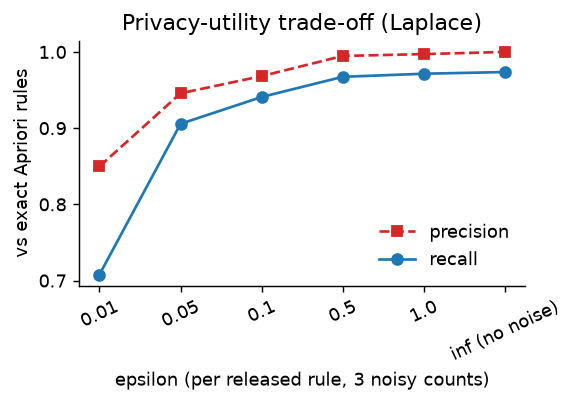

,epsilon,precision,recall,n_rules,F1
0,0.01,0.850,0.708,1011.3,0.772
1,0.05,0.946,0.906,1162.6,0.925
2,0.1,0.968,0.941,1179.7,0.954
3,0.5,0.995,0.967,1180.6,0.981
4,1.0,0.997,0.971,1182.6,0.984
5,inf (no noise),1.000,0.974,1182.0,0.987


In [17]:
print("E8 privacy", flush=True)
cnt_ante = {}
Mtr = Xtr.values
col_ix = {c: i for i, c in enumerate(Xtr.columns)}
base_cnt = Mtr.sum(0)
cd = nn_cand.copy()
na_ = np.array([np.logical_and.reduce(Mtr[:, [col_ix[i] for i in a]], axis=1).sum() for a in cd["antecedent"]])
nac_ = cd["count"].values
nc_ = np.array([base_cnt[col_ix[c]] for c in cd["consequent"]])
n = len(Xtr)
priv = []
rng = np.random.default_rng(SEED)
for eps in (0.01, 0.05, 0.1, 0.5, 1.0, np.inf):
    res = []
    for rep in range(10):
        if np.isinf(eps):
            a_n, ac_n, c_n = na_, nac_, nc_
        else:
            sc = 3.0 / eps                                       # three count queries, eps/3 each (L1 sensitivity 1)
            a_n = na_ + rng.laplace(0, sc, len(na_)); ac_n = nac_ + rng.laplace(0, sc, len(na_)); c_n = nc_ + rng.laplace(0, sc, len(na_))
        conf = ac_n / np.maximum(a_n, 1); lift = conf / np.maximum(c_n / n, 1e-9); sup = ac_n / n
        keep = (sup >= MIN_SUP) & (conf >= MIN_CONF) & (lift >= MIN_LIFT)
        k = set(cd["key"][keep])
        res.append((len(k & K_ap) / max(len(k), 1), len(k & K_ap) / len(K_ap), len(k)))
    res = np.array(res)
    priv.append({"epsilon": "inf (no noise)" if np.isinf(eps) else eps, "precision": res[:, 0].mean(), "recall": res[:, 1].mean(), "n_rules": res[:, 2].mean()})
pr = pd.DataFrame(priv)
pr["F1"] = 2 * pr.precision * pr.recall / (pr.precision + pr.recall)
pr.to_csv("results/e8_privacy_utility.csv", index=False)
S["e8"] = pr.to_dict("records")
S["k_anonymity"] = {"min_rule_support_count": int(ap["count"].min()), "median_support_count": int(ap["count"].median())}
fig, ax = plt.subplots(figsize=(4.6, 3.2))
xs_ = [str(e) for e in pr["epsilon"]]
ax.plot(xs_, pr["precision"], "s--", label="precision", color=C_AP); ax.plot(xs_, pr["recall"], "o-", label="recall", color=C_NN)
ax.set_xlabel("epsilon (per released rule, 3 noisy counts)"); ax.set_ylabel("vs exact Apriori rules"); ax.legend(frameon=False)
ax.set_title("Privacy-utility trade-off (Laplace)")
plt.xticks(rotation=25)
save("fig_privacy")

display(pr.round(3))


### workflow diagram
**Workflow diagram** (Figure 1 of the report) and the final summary file `results/summary.json`.

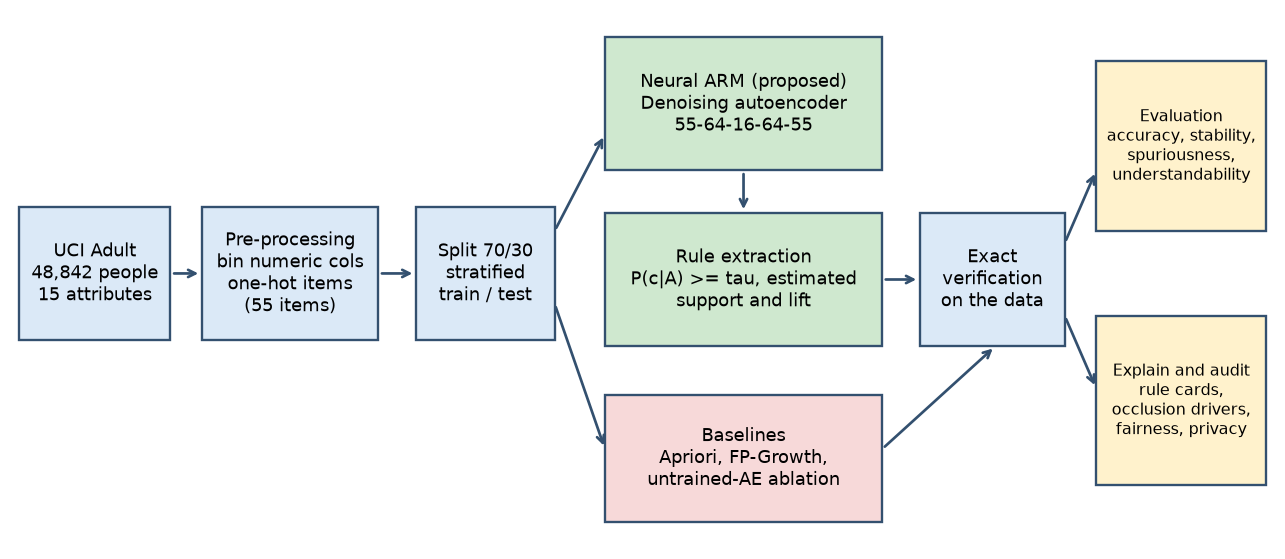

done in 8.6 min
done in 8.6 min


In [18]:
import workflow_fig
workflow_fig.draw("figures/fig_workflow.png")

S["total_runtime_min"] = (time.time() - t_start) / 60
json.dump(S, open("results/summary.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("done in %.1f min" % S["total_runtime_min"])
print('done in %.1f min' % S['total_runtime_min'])


## 3. Key results at a glance

In [19]:
import json
S = json.load(open("results/summary.json"))
e1 = pd.read_csv("results/e1_main_comparison.csv").set_index("method")
print(f"Neural (verified) recovers {e1.loc['Neural (verified)','recall_vs_apriori']:.1%} of Apriori's {int(e1.loc['Apriori','n_rules'])} rules, precision {e1.loc['Neural (verified)','precision_vs_apriori']:.1%}")
print(f"Network estimate vs true confidence: r = {S['ae_corr_p_conf']:.2f}, mean abs. error {S['ae_mae_p_conf']:.3f}; only {e1.loc['Neural (verified)','proposal_precision']:.1%} of raw proposals survive verification")
print("Mean pairwise Jaccard (bootstrap, full train):", {r['method']: round(r['mean_jaccard'], 3) for r in S['e4'] if r['setting'] == 'full train'})
print("False rules on permuted data, n=1000:", S['e5_null']['1000'])
print(f"Share of rules mentioning sex or race: {S['audit']['share_either']:.1%}")

Neural (verified) recovers 97.4% of Apriori's 1214 rules, precision 100.0%
Network estimate vs true confidence: r = 0.92, mean abs. error 0.034; only 70.1% of raw proposals survive verification
Mean pairwise Jaccard (bootstrap, full train): {'Apriori': 0.943, 'Neural (verified)': 0.937, 'Neural consensus': 0.921}
False rules on permuted data, n=1000: {'Apriori': 5.2, 'Neural (verified)': 4.0, 'Neural consensus': 3.8}
Share of rules mentioning sex or race: 57.4%


## 4. Download the outputs (optional)
Zips `results/` and `figures/` so the tables and PNGs can be saved or attached to the report.

In [20]:
import shutil
shutil.make_archive("neural_arm_outputs", "zip", ".", "results")
shutil.make_archive("neural_arm_figures", "zip", ".", "figures")
try:
    from google.colab import files
    files.download("neural_arm_outputs.zip"); files.download("neural_arm_figures.zip")
except Exception:
    print("Not on Colab: zips are in the current folder.")

Not on Colab: zips are in the current folder.


---
**Notes.** The neural miner is as accurate and stable as exhaustive Apriori on this small dataset, not better; its value is the verified, explained and audited pipeline. Limitations and future work are discussed in the report.